# Local DPO pilot
Independent local copy of dpo_train.ipynb. Uses DL_Final, the local Qwen weights and MedQA files, 64 preference pairs, 32 validation questions, and 10 optimizer steps. Original-model baseline evaluation is disabled. Outputs use a separate local directory. No full-data training is started.

In [1]:
from pathlib import Path
import sys, os, json, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO = Path('/content/drive/MyDrive/medqa-calibration')
else:
    here = Path.cwd().resolve()
    REPO = here if (here / 'train/dpo/train.py').is_file() else here.parent
assert (REPO / 'train/dpo/train.py').is_file(), 'Set REPO to the repository root.'
print('Repository:', REPO)

Repository: C:\Users\RyanW\OneDrive\Desktop\CS 5787 Deep Learning\Final Project\medqa-calibration


In [2]:
import torch, importlib.metadata
assert torch.cuda.is_available(), 'CUDA is required.'
print('Python:', sys.executable)
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, 'CUDA:', torch.version.cuda)
print('BF16 supported:', torch.cuda.is_bf16_supported())
assert 'DL_Final' in sys.executable, 'Select the DL_Final kernel.'


Python: C:\Users\RyanW\miniconda3\envs\DL_Final\python.exe
GPU: NVIDIA GeForce RTX 5070 Ti
PyTorch: 2.11.0+cu128 CUDA: 12.8
BF16 supported: True


## Dependencies
Activate `DL_Final` before opening this notebook locally. Retain Colab's installed CUDA-enabled PyTorch. Set `INSTALL_DEPENDENCIES=True` only when the DPO dependencies need installation; restart the kernel afterward if the notebook asks for it.

In [3]:
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(REPO / 'train/dpo/requirements-local.txt')])
import importlib.metadata
for name in ['torch', 'transformers', 'trl', 'peft', 'datasets', 'accelerate', 'bitsandbytes']:
    try:
        print(name, importlib.metadata.version(name))
    except importlib.metadata.PackageNotFoundError:
        print(name, 'not installed')

torch 2.11.0+cu128
transformers 4.57.6
trl 1.16.0
peft 0.18.0
datasets 5.0.1
accelerate 1.15.0
bitsandbytes 0.49.2


In [4]:
def run_command(command):
    process = subprocess.Popen(command, cwd=REPO, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                               env=dict(os.environ, PYTHONIOENCODING='utf-8', PYTHONUNBUFFERED='1'))
    log_dir = REPO / 'outputs/dpo_local_pilot_execution'
    log_dir.mkdir(parents=True, exist_ok=True)
    try:
        with (log_dir / 'commands.log').open('a', encoding='utf-8') as log:
            log.write('Command: ' + repr(command) + '\n')
            for line in process.stdout:
                print(line, end='', flush=True)
                log.write(line)
                log.flush()
        if process.wait() != 0:
            raise RuntimeError('Command failed; inspect the output above.')
    except BaseException:
        if process.poll() is None:
            process.terminate()
            process.wait()
        raise
    finally:
        process.stdout.close()


## One-time original-model baseline
Run this optional stage before the first training experiment. It evaluates all 500 fixed validation questions and the full official MedQA test split, without adapters or answer generation. Subsequent experiments can leave `RUN_BASELINE=False` and reuse the saved results. Use the same base revision, quantization, and precision for comparable results; if these change, use a separate baseline output directory. Existing outputs are protected from overwrite. A failed partial run requires a new output directory. Test scores must never guide hyperparameter or checkpoint selection.


In [5]:
RUN_BASELINE = False  # Enable for the first run only; later runs display saved results.
BASELINE_SOURCE = 'local'
BASELINE_MODEL = 'Qwen/Qwen2.5-3B-Instruct' if BASELINE_SOURCE == 'hf' else str(REPO.parent / 'Qwen2.5-3B-Instruct')
BASELINE_QUANTIZATION = '4bit'
BASELINE_COMPUTE_DTYPE = 'auto'
BASELINE_BATCH_SIZE = 4
BASELINE_OUTPUT = REPO / 'outputs/base_medqa_4bit'


In [6]:
if RUN_BASELINE:
    command = [sys.executable, '-u', '-m', 'train.dpo.baseline',
               '--source', BASELINE_SOURCE, '--model', BASELINE_MODEL,
               '--quantization', BASELINE_QUANTIZATION, '--compute_dtype', BASELINE_COMPUTE_DTYPE,
               '--batch_size', str(BASELINE_BATCH_SIZE), '--output_dir', str(BASELINE_OUTPUT)]
    if BASELINE_SOURCE == 'local':
        command += ['--local_train_file', str(REPO.parent / 'MedQA-USMLE-4-options/phrases_no_exclude_train.jsonl'),
                    '--local_test_file', str(REPO.parent / 'MedQA-USMLE-4-options/phrases_no_exclude_test.jsonl')]
    run_command(command)
else:
    print('Baseline evaluation disabled; existing results will be displayed if available.')


Baseline evaluation disabled; existing results will be displayed if available.


In [7]:
import pandas as pd
from IPython.display import display
if (BASELINE_OUTPUT / 'summary.json').is_file():
    baseline = json.loads((BASELINE_OUTPUT / 'summary.json').read_text())
    manifest = json.loads((BASELINE_OUTPUT / 'manifest.json').read_text())
    display(pd.DataFrame([{'split': name, 'questions': manifest['counts'][name], **metrics}
                          for name, metrics in baseline.items()]))
    print('Saved baseline configuration:', manifest['model'], manifest['quantization'], manifest['compute_dtype'])
    print('Test scores are descriptive only and must not be used for hyperparameter selection.')
else:
    print('No completed baseline exists. Set RUN_BASELINE=True to evaluate the original model.')


No completed baseline exists. Set RUN_BASELINE=True to evaluate the original model.


## Run configuration
`PILOT=True` uses 64 pairs, 32 validation questions, and 10 updates in a separate directory. Set it to False for full training. Changing a pilot into a full run requires a new output directory. Use `STOP_AFTER_STEP` instead when pausing a full run while preserving its learning-rate schedule.

Keep the output directory on Google Drive in Colab. Resume requires an existing complete checkpoint and matching arguments.

In [2]:
SOURCE = 'local'
MODEL = 'Qwen/Qwen2.5-3B-Instruct' if SOURCE == 'hf' else str(REPO.parent / 'Qwen2.5-3B-Instruct')
LOCAL_TRAIN_FILE = REPO.parent / 'MedQA-USMLE-4-options/phrases_no_exclude_train.jsonl'
DATA_FILE = REPO / 'outputs/medqa5000_L4_seed42_qpb2/selection_seed42/dpo.jsonl'
PILOT = True
RUN_TRAINING = True
RESUME = False
SEED = 1
QUANTIZATION = '4bit'
EPOCHS = 1
BATCH_SIZE = 1
GRADIENT_ACCUMULATION = 16
MAX_LENGTH = 2048
LEARNING_RATE = 5e-6
BETA = 0.1
LORA_DROPOUT = 0.05
STOP_AFTER_STEP = 0
OUTPUT = REPO / 'outputs' / 'dpo_local_pilot_20261109_seed1'
COMMON = [sys.executable, '-u', '-m', 'train.dpo.train', '--source', SOURCE,
          '--model', MODEL, '--data_file', str(DATA_FILE), '--output_dir', str(OUTPUT),
          '--seed', str(SEED), '--quantization', QUANTIZATION, '--num_train_epochs', str(EPOCHS),
          '--batch_size', str(BATCH_SIZE), '--gradient_accumulation_steps', str(GRADIENT_ACCUMULATION),
          '--max_length', str(MAX_LENGTH), '--learning_rate', str(LEARNING_RATE), '--beta', str(BETA),
          '--lora_dropout', str(LORA_DROPOUT), '--no-baseline_validation', '--eval_batch_size', '2', '--logging_steps', '1']
if SOURCE == 'local':
    COMMON += ['--local_train_file', str(LOCAL_TRAIN_FILE)]
if PILOT:
    COMMON += ['--n_pairs', '64', '--n_val', '32', '--max_steps', '10']
if STOP_AFTER_STEP:
    COMMON += ['--stop_after_step', str(STOP_AFTER_STEP)]
print('Output:', OUTPUT)
print('Training enabled:', RUN_TRAINING)

Output: C:\Users\RyanW\OneDrive\Desktop\CS 5787 Deep Learning\Final Project\medqa-calibration\outputs\dpo_local_pilot_20261109_seed1
Training enabled: True


## Data and token-length check
This checks source hashes, question identities, held-out separation, pair labels, and chat-template lengths. It loads the tokenizer, not model weights. Archived raw samples are not needed.

In [9]:
run_command(COMMON + ['--check_data'])


{


  "pairs": 3322,


  "validation_questions": 500,


  "data_sha256": "1e77874d638a4004f698c6aae82131728f7a9f45d0210e716991518bb61a1cab",


  "retained_ids_sha256": "ae402798b02c37379b7f0c1c167599ac5fc6f0a9b4e51f21e709bdcc69867d97",


  "split_sha256": "f930fa7a4be2ec57eef8f79e207438f398b4597341a5406232b2df9506e8714f",


... (7 outputs left out)

    "mean_sequence_tokens": 675.6015625,


    "total_sequence_tokens": 86477


  }


}


## Train or resume
Default: NF4 QLoRA, rank 16, alpha 32, active LoRA dropout 0.05, and a fixed base reference. No new responses are sampled. The original-model baseline is handled by the optional stage above and is not repeated here. Adapter validation runs after each epoch. Best-adapter selection uses validation accuracy, then NLL. Test metrics never select a checkpoint. Training checkpoints include optimizer and RNG state; `best_adapter` is for evaluation, not resume.


In [10]:
if RUN_TRAINING:
    run_command(COMMON + (['--resume'] if RESUME else []))
else:
    print('Training is disabled. Review the configuration and set RUN_TRAINING=True to start.')

W1109 09:19:44.416000 14976 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]C:\Users\RyanW\miniconda3\envs\DL_Final\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.


  torch._check_is_size(blocksize)


Loading checkpoint shards:  50%|█████     | 1/2 [00:02<00:02,  2.85s/it]


Loading checkpoint shards: 100%|██████████| 2/2 [00:04<00:00,  2.10s/it]


Loading checkpoint shards: 100%|██████████| 2/2 [00:04<00:00,  2.22s/it]


... (155 outputs left out)

{'train_runtime': 146.3674, 'train_samples_per_second': 1.093, 'train_steps_per_second': 0.068, 'train_loss': 0.6614550054073334, 'epoch': 2.5}


100%|██████████| 10/10 [02:26<00:00, 14.62s/it]


100%|██████████| 10/10 [02:26<00:00, 14.64s/it]


Training finished. Artifacts: C:\Users\RyanW\OneDrive\Desktop\CS 5787 Deep Learning\Final Project\medqa-calibration\outputs\dpo_local_pilot_20261109_seed1


## Results
Review training loss separately from medical answer accuracy. ECE, Brier, NLL, and high-confidence errors measure confidence reliability. Timing estimates exclude validation and checkpoint overhead.

,n,accuracy,mean_confidence,ece,brier,nll,hc_wrong_rate,hc_wrong_count,mean_conf_wrong,hc_count,hc_accuracy,mean_letter_mass,min_letter_mass
0,32,0.4375,0.972826,0.535326,1.057441,5.349117,0.46875,15,0.956559,29,0.482759,1.0,0.999999


{
  "global_step": 10,
  "epoch": 2.5,
  "stopped_early": false,
  "steady_step_seconds": 13.972164414285706,
  "estimated_training_seconds_per_epoch": 55.88865765714282,
  "peak_allocated_gib": 5.921821117401123
}
Best adapter: C:\Users\RyanW\OneDrive\Desktop\CS 5787 Deep Learning\Final Project\medqa-calibration\outputs\dpo_local_pilot_20261109_seed1\best_adapter


,step,epoch,loss,grad_norm,learning_rate,entropy,num_tokens,logits/chosen,logits/rejected,mean_token_accuracy,...,rewards/rejected,rewards/accuracies,rewards/margins,logps/chosen,logps/rejected,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
1,2,0.50,0.6931,6.833497,5.000000e-06,1.216034,43712.0,-1.167385,-1.155409,0.627566,...,0.000000,0.0000,0.000000,-532.092033,-536.354694,NaN,NaN,NaN,NaN,NaN
2,3,0.75,0.6881,6.507011,4.849232e-06,1.187728,64533.0,-1.272628,-1.266462,0.646425,...,0.008469,0.5000,0.012395,-444.465368,-498.514082,NaN,NaN,NaN,NaN,NaN
3,4,1.00,0.7039,6.434325,4.415111e-06,1.170145,86477.0,-1.193979,-1.237186,0.644451,...,0.002869,0.6250,-0.019365,-489.547937,-483.532591,NaN,NaN,NaN,NaN,NaN
4,5,1.25,0.6564,6.131198,3.750000e-06,1.158181,108147.0,-1.263345,-1.272365,0.654017,...,-0.023249,0.6875,0.077781,-481.338736,-473.520090,NaN,NaN,NaN,NaN,NaN
5,6,1.50,0.6292,6.258935,2.934120e-06,1.186816,128481.0,-1.266318,-1.159678,0.643865,...,-0.068420,0.8125,0.136174,-443.951105,-487.031452,NaN,NaN,NaN,NaN,NaN
6,7,1.75,0.6516,6.316012,2.065880e-06,1.223880,151605.0,-1.161609,-1.186256,0.623224,...,-0.069734,0.8125,0.088518,-568.898136,-538.954645,NaN,NaN,NaN,NaN,NaN
7,8,2.00,0.6359,6.109563,1.250000e-06,1.166269,172954.0,-1.212728,-1.283410,0.633744,...,-0.075696,0.8750,0.120414,-478.732769,-517.961372,NaN,NaN,NaN,NaN,NaN
8,9,2.25,0.6280,6.039477,5.848889e-07,1.186141,196662.0,-1.280633,-1.221115,0.643153,...,-0.059802,0.8750,0.137299,-571.758312,-521.018669,NaN,NaN,NaN,NaN,NaN
9,10,2.50,0.6352,5.926746,1.507684e-07,1.159673,217102.0,-1.209717,-1.243734,0.644852,...,-0.096042,1.0000,0.120834,-429.581446,-492.447241,NaN,NaN,NaN,NaN,NaN
10,10,2.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,146.3674,1.093,0.068,3.914754e+15,0.661455


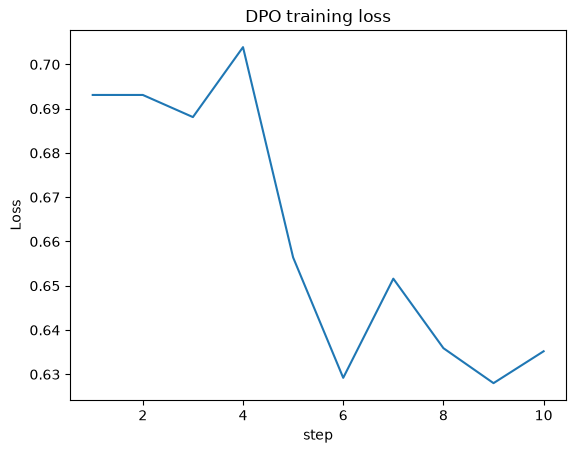

In [3]:
import pandas as pd
from IPython.display import display
summary_file = OUTPUT / 'training_summary.json'
if summary_file.is_file():
    summary = json.loads(summary_file.read_text())
    display(pd.DataFrame([summary['best_validation']['metrics']]))
    print(json.dumps({k: summary[k] for k in ['global_step', 'epoch', 'stopped_early',
          'steady_step_seconds', 'estimated_training_seconds_per_epoch', 'peak_allocated_gib']}, indent=2))
    print('Best adapter:', OUTPUT / 'best_adapter')
else:
    print('No completed training summary exists for this output directory.')
log = OUTPUT / 'training_metrics.jsonl'
if log.is_file():
    history = pd.read_json(log, lines=True)
    display(history.tail(10))
    if 'loss' in history:
        import matplotlib.pyplot as plt
        history.dropna(subset=['loss']).plot(x='step', y='loss', title='DPO training loss', legend=False)
        plt.ylabel('Loss')
        plt.show()

## Final experiments
After validation-based configuration selection, repeat with a second seed and a separate output directory. Evaluate selected adapters on the MedQA test set and transfer datasets using the existing evaluator. Do not use those scores to choose training checkpoints. See `train/dpo/README.txt` for commands and artifact descriptions.

## Reopening this completed pilot
The saved outputs document the completed 10-step run. To refresh the report without retraining, run `python -m train.dpo.run_local_training --report-only` from the repository root with DL_Final active. For another pilot, select a new output directory. The max_steps=10 setting overrides the one-epoch setting and covers 2.5 passes over these 64 pairs.